# S-shaped growth: epidemics and diffusion in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/07-s-shaped.ipynb)

This notebook is the Python companion to the [S-shaped growth](https://waelrash1.github.io/loopbricks/#/learn/s-shaped) module. You will watch a reinforcing loop run into a limit, build a small epidemic model and find its tipping point, see why an epidemic stops before everyone is ill, and compare ways a new product can spread. It uses the LoopBricks molecules Constrained Growth, Population Growth and Diffusion, plus an epidemic model written by hand.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Growth that meets a limit

In **Constrained Growth**, a population grows by 18% a year, but crowding removes a share of that growth that rises with the population: at the carrying capacity of 200, crowding cancels growth completely. Early on the reinforcing loop dominates and growth looks exponential; later the balancing loop takes over and the population levels off. The result is the S-shaped, or *logistic*, curve.

Constrained Growth

Stocks:
  Population = INTEG(Growth − Crowding deaths, 10)

Flows:
  Growth = Population * Fractional_growth_rate
  Crowding deaths = Population * Fractional_growth_rate * (Population / Carrying_capacity)

Variables:
  Growth rate = 18
  Carrying capacity = 200
  Fractional growth rate = Growth_rate / 100
Net growth peaks in year 16.4 at 9.0 a year, when the population is 99.6


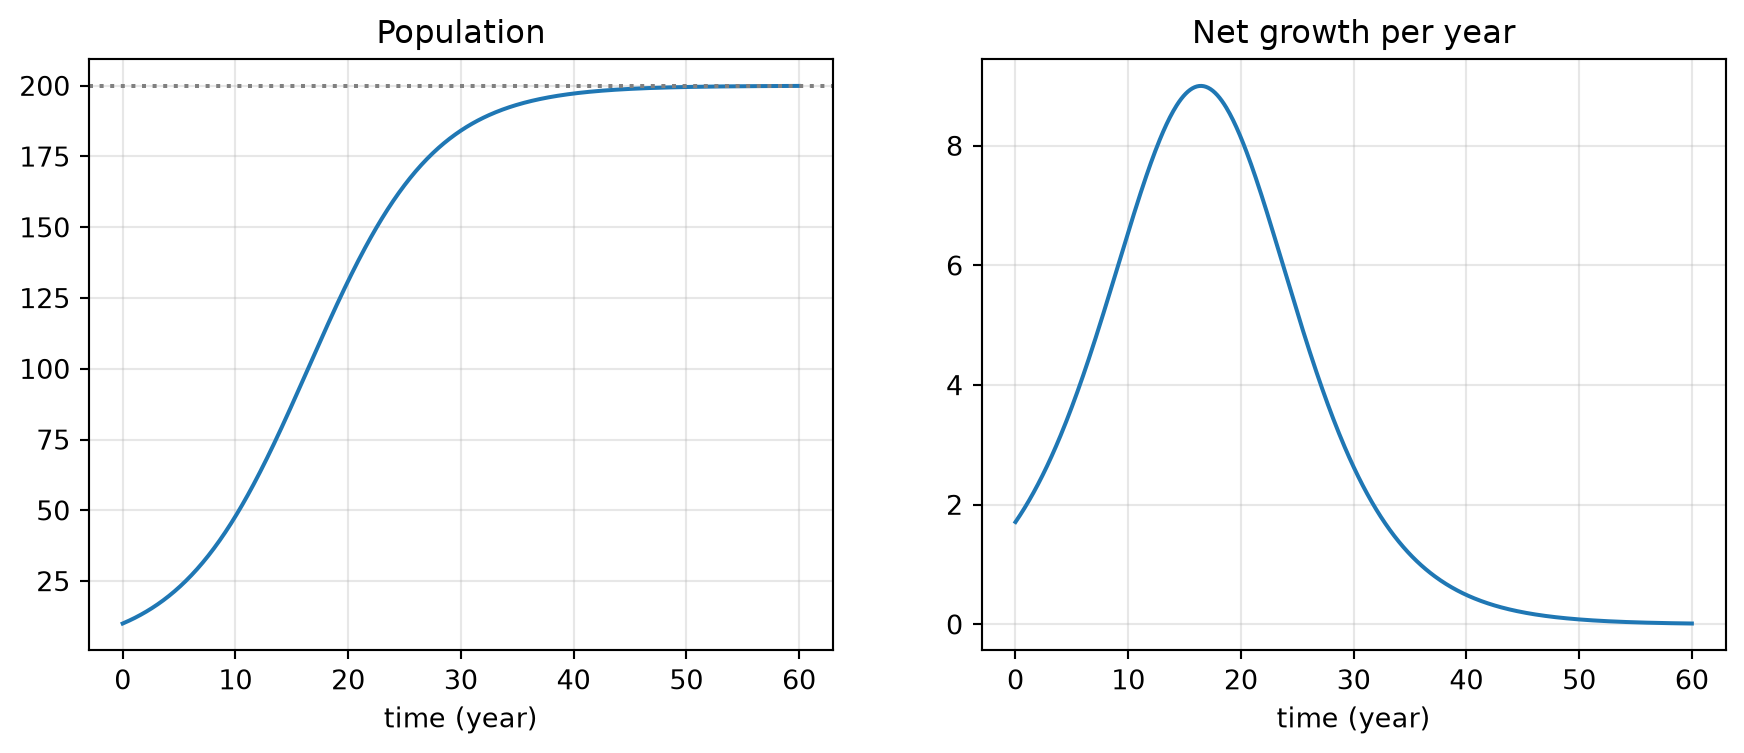

In [2]:
lg = lb.molecule("logistic")
print(lg.equations())
d = lg.run()
d["Net growth"] = d["Growth"] - d["Crowding deaths"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
d["Population"].plot(ax=a1, title="Population"); a1.axhline(200, ls=":", c="grey")
d["Net growth"].plot(ax=a2, title="Net growth per year")
for a in (a1, a2): a.grid(alpha=0.3)

peak = d["Net growth"].idxmax()
print(f"Net growth peaks in year {peak} at {d['Net growth'].max():.1f} a year, "
      f"when the population is {d.loc[peak, 'Population']:.1f}")

The net growth is a hill, not a ramp. It is largest in year 16.4, when the population is about 100, half the carrying capacity. Before that point each year adds more than the last (the curve bends upward); after it each year adds less (the curve bends over). That turning point is the *inflection point*, and for the logistic it always sits at half the limit.

**Try it.** Raise the carrying capacity to 350. Where is the inflection point now? Then compare the population in years 5 and 10 for capacities of 200, 350 and a huge 100000. Could you tell the limits apart from the first 5 years of data?

<details><summary>Show a worked answer</summary>

With a capacity of 350, net growth peaks in year 19.7 at a population of 175, again half the limit. In year 5 the three runs give 22.8, 23.5 and 24.4: all within 7% of each other, so early data say almost nothing about the limit. By year 10 they are 47.9, 52.3 and 59.5, and the gap keeps widening. An S-curve looks exponential until it does not.
</details>

In [3]:
for K in (200, 350, 100000):
    run = lg.run(carrying_capacity=K)
    net = run["Growth"] - run["Crowding deaths"]
    print(f"capacity {K:>6}: year 5 {run.loc[5.0, 'Population']:5.1f}, year 10 {run.loc[10.0, 'Population']:5.1f}, "
          f"net growth peaks in year {net.idxmax()} at population {run.loc[net.idxmax(), 'Population']:.0f}")

capacity    200: year 5  22.8, year 10  47.9, net growth peaks in year 16.4 at population 100
capacity    350: year 5  23.5, year 10  52.3, net growth peaks in year 19.7 at population 175
capacity 100000: year 5  24.4, year 10  59.5, net growth peaks in year 51.6 at population 50188


## 2. The tipping point of an epidemic

At the very start of an outbreak almost everyone is susceptible, so the infected group behaves like a population with births and deaths: new infections are its births and recoveries its deaths. **Population Growth** shows the three possibilities. If births outrun deaths the stock grows, if deaths win it dies out, and if they balance it stays put.

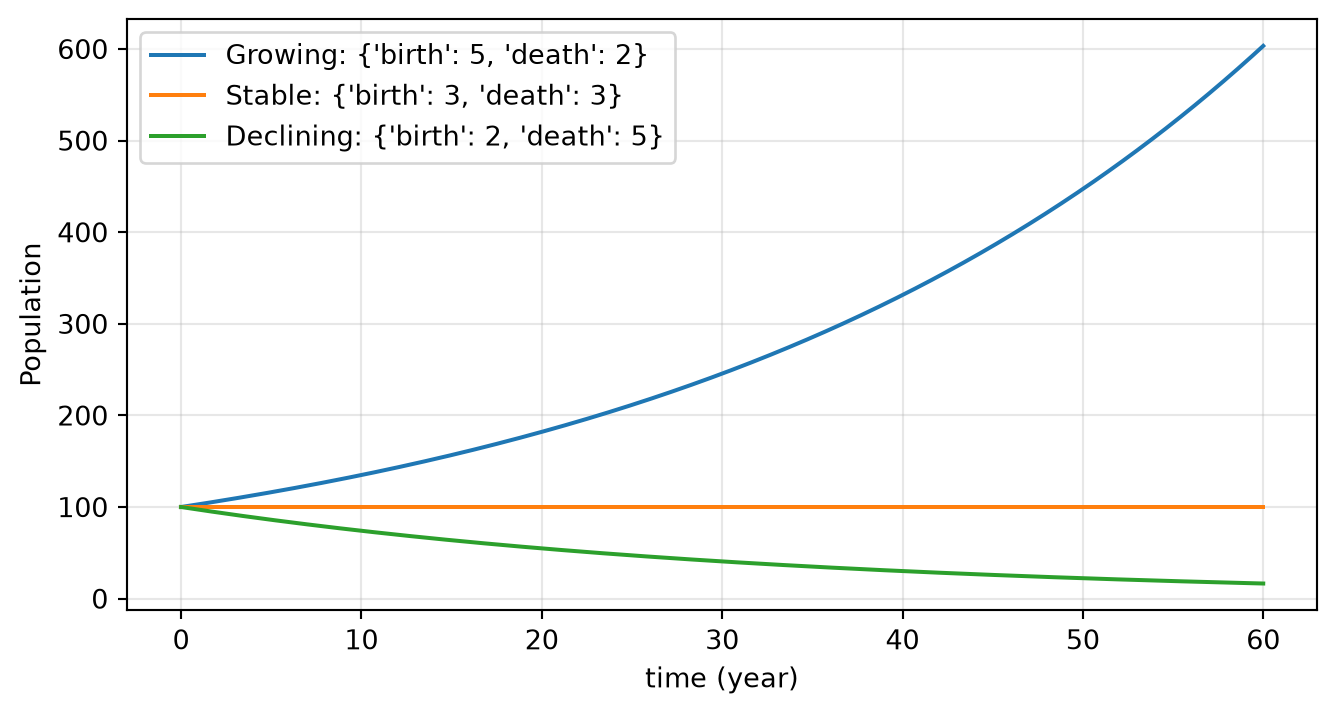

In [4]:
pg = lb.molecule("growth")
fig, ax = plt.subplots(figsize=(8, 4))
for label in ("Growing", "Stable", "Declining"):
    pg.run(preset=label)["Population"].plot(ax=ax, label=f"{label}: {pg.preset(label)}")
ax.set_ylabel("Population"); ax.legend(); ax.grid(alpha=0.3)

For an infection, the ratio of the two rates is the **contact number**: how many people one infected person infects over the whole illness. It is contacts per day × the chance that a contact passes on the infection × the days a person stays infectious. Above 1, an outbreak takes off; below 1, it fizzles.

Here is a small epidemic model, written by hand: 10000 people, 10 of them infected at the start. As people recover, the pool of susceptible people shrinks, and that is the limit that bends the curve.

contact number 0.75: peak of    10 infected on day   0.0
contact number 1.50: peak of   639 infected on day 114.5
contact number 2.00: peak of  1548 infected on day  68.2
contact number 3.00: peak of  3037 infected on day  39.0


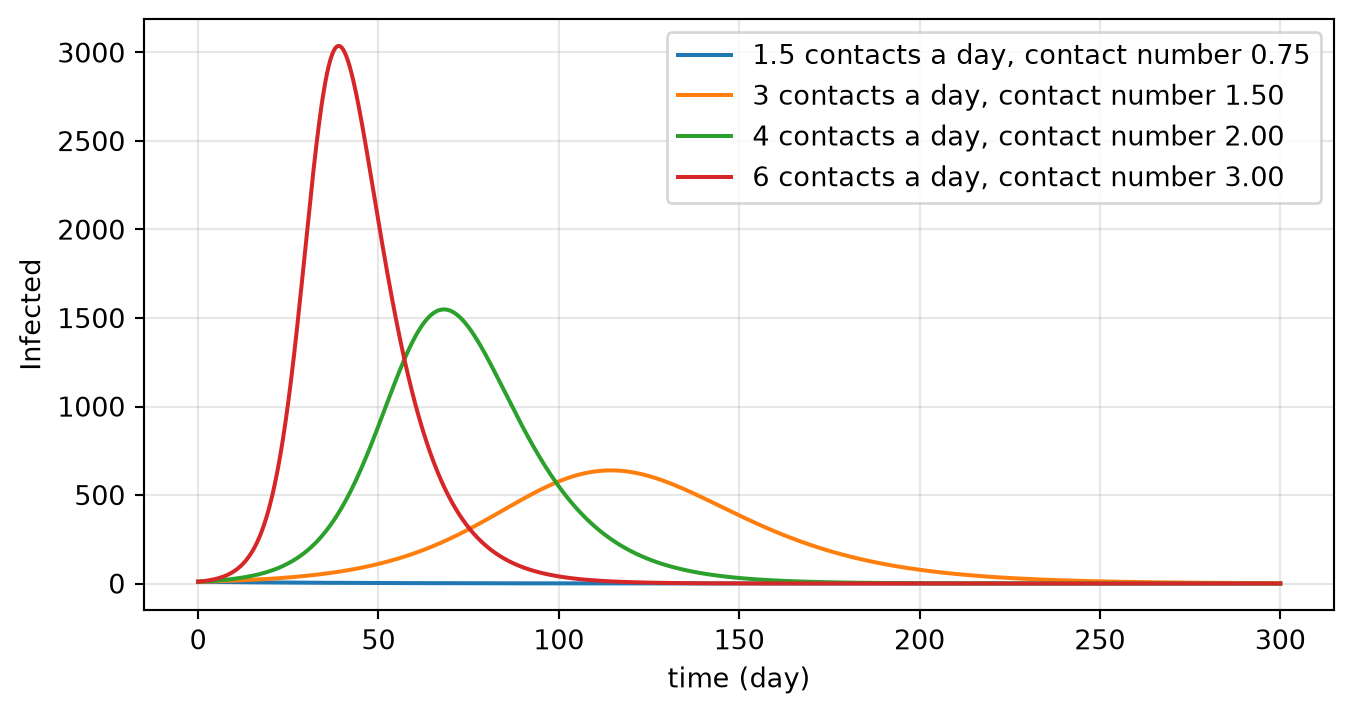

In [5]:
epidemic = lb.Model.from_spec({
    "name": "Epidemic", "timeUnit": "day", "T": 300, "dt": 0.25,
    "stocks": [
        {"id": "s", "name": "Susceptible", "init": "9990", "x": 0, "y": 0},
        {"id": "i", "name": "Infected", "init": "10", "x": 0, "y": 0},
        {"id": "r", "name": "Recovered", "init": "0", "x": 0, "y": 0},
    ],
    "flows": [
        {"id": "inf", "name": "Infection", "from": "s", "to": "i",
         "eq": "Contact_rate * Infectivity * Infected * Susceptible / Population", "x": 0, "y": 0},
        {"id": "rec", "name": "Recovery", "from": "i", "to": "r", "eq": "Infected / Illness_duration", "x": 0, "y": 0},
    ],
    "vars": [
        {"id": "c", "name": "Contact rate", "eq": "4", "x": 0, "y": 0},        # contacts per day
        {"id": "p", "name": "Infectivity", "eq": "0.05", "x": 0, "y": 0},      # chance a contact infects
        {"id": "d", "name": "Illness duration", "eq": "10", "x": 0, "y": 0},   # days
        {"id": "n", "name": "Population", "eq": "10000", "x": 0, "y": 0},
    ],
})

fig, ax = plt.subplots(figsize=(8, 4))
for c in (1.5, 3, 4, 6):
    run = epidemic.run(contact_rate=c)
    run["Infected"].plot(ax=ax, label=f"{c} contacts a day, contact number {c * 0.05 * 10:.2f}")
    print(f"contact number {c * 0.05 * 10:.2f}: peak of {run['Infected'].max():5.0f} infected on day {run['Infected'].idxmax():5.1f}")
ax.set_ylabel("Infected"); ax.legend(); ax.grid(alpha=0.3)

With a contact number of 0.75 the 10 cases never become more than 10: the outbreak dies away. At 1.5 it takes off slowly and peaks after more than 100 days; at 3 it peaks near day 39 with about 3000 people ill at once. Small changes in how often people meet push the system over the threshold or keep it below. That is why distancing, hand washing and shorter infectious periods all matter: each one lowers the contact number.

**Try it.** Shorten the illness to 4 days (`illness_duration=4`) with 6 contacts a day. What is the contact number, and what happens?

<details><summary>Show a worked answer</summary>

The contact number is 6 × 0.05 × 4 = 1.2, just above 1. The outbreak does take off, but slowly: the run below shows a peak of only about 160 infected, on day 82, and around 6800 people are never infected. Cutting the infectious period works on the same loop as cutting contacts.
</details>

In [6]:
run = epidemic.run(contact_rate=6, illness_duration=4)
print(f"Peak {run['Infected'].max():.0f} infected on day {run['Infected'].idxmax()}; "
      f"{run['Susceptible'].iloc[-1]:.0f} people never infected")

Peak 156 infected on day 81.75; 6819 people never infected


## 3. Why an epidemic burns out early

An epidemic does not end because everyone has been ill. It turns the corner when the susceptible pool is so small that each case passes the infection to fewer than one new person on average. That happens when the share still susceptible falls to 1 / contact number. The people who are immune then protect the rest: this is **herd immunity**.

In [7]:
for c in (3, 4, 6):
    R = c * 0.05 * 10
    run = epidemic.run(contact_rate=c)
    peak = run["Infected"].idxmax()
    print(f"contact number {R:.1f}: susceptible at the peak {run.loc[peak, 'Susceptible']:5.0f} "
          f"(10000 / {R:.1f} = {10000 / R:5.0f}), never infected {run['Susceptible'].iloc[-1]:5.0f}")

contact number 1.5: susceptible at the peak  6654 (10000 / 1.5 =  6667), never infected  4156
contact number 2.0: susceptible at the peak  4967 (10000 / 2.0 =  5000), never infected  2014
contact number 3.0: susceptible at the peak  3292 (10000 / 3.0 =  3333), never infected   579


In every run the peak comes when the susceptible group has shrunk to 10000 divided by the contact number. Infections keep going after the peak, so the epidemic overshoots the herd immunity level, but it still leaves people untouched: about 2000 with a contact number of 2, and about 600 with 3.

**Try it.** A vaccine protects a share of people before the outbreak starts. With a contact number of 2, roughly what share must be vaccinated so that the outbreak cannot take off at all? Check by changing the `init` of Susceptible and Recovered in the spec.

<details><summary>Show a worked answer</summary>

The outbreak cannot grow if the susceptible share is already below 1 / 2 = 50%, so about half the population must be immune. In the cell below, with 5100 people vaccinated the number of infected only falls from the first day; with 4000 vaccinated there is still a slow outbreak, peaking at about 97 infected on day 176.
</details>

In [8]:
import copy
for vaccinated in (4000, 5100):
    spec = copy.deepcopy(epidemic.spec)
    spec["model"]["stocks"][0]["init"] = str(9990 - vaccinated)
    spec["model"]["stocks"][2]["init"] = str(vaccinated)
    run = lb.Model.from_spec(spec).run(contact_rate=4)
    print(f"{vaccinated} vaccinated: infected peak {run['Infected'].max():6.1f} on day {run['Infected'].idxmax()}")

4000 vaccinated: infected peak   96.9 on day 176.0
5100 vaccinated: infected peak   10.0 on day 0.0


## 4. Products spread like infections

New products, ideas and habits spread in much the same way. In **Diffusion** (the Bass model) people adopt for two reasons: some are reached by advertising or try it on their own (*innovation*, `p`), and others copy adopters they meet (*imitation*, `q`). Imitation is a reinforcing loop, and the shrinking pool of potential adopters is the limit.

Word-of-mouth : adoption peaks in week 15.3, half the market adopted by week 15.9
Ad-driven     : adoption peaks in week  2.5, half the market adopted by week 13.1
Viral         : adoption peaks in week 12.1, half the market adopted by week 12.2


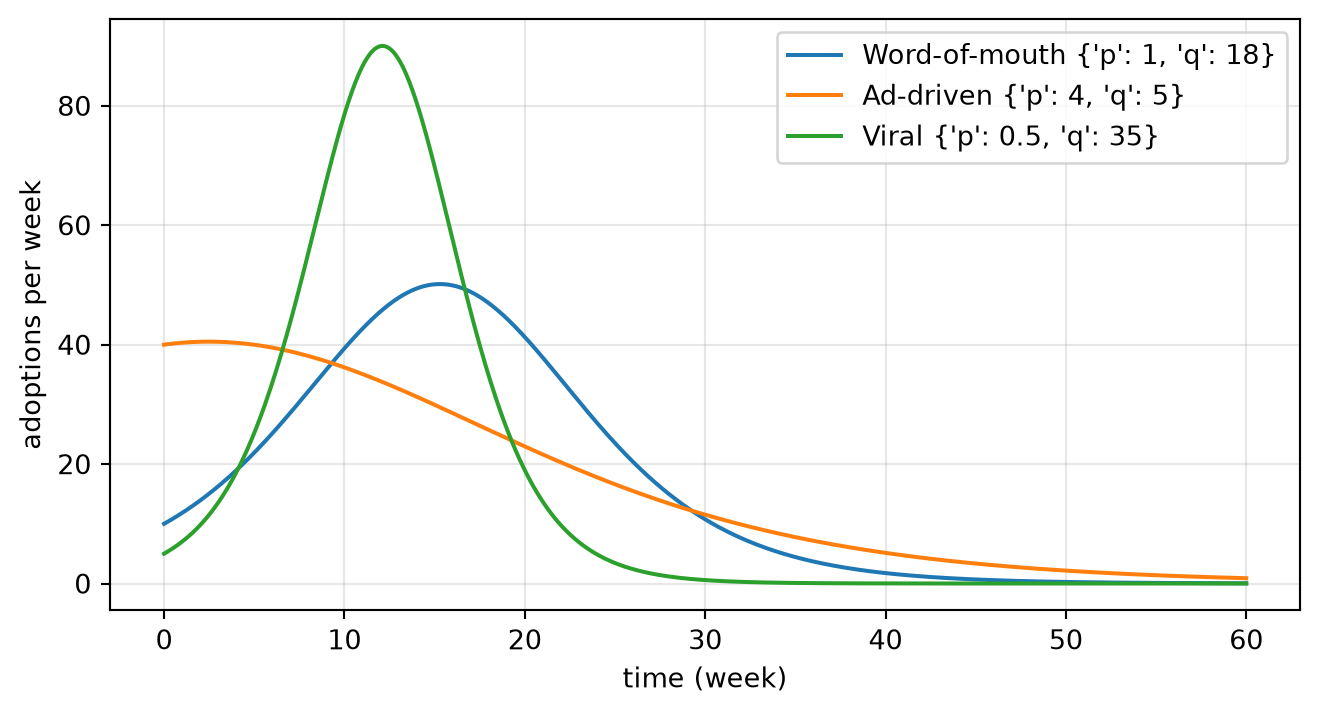

In [9]:
dif = lb.molecule("diffusion")
fig, ax = plt.subplots(figsize=(8, 4))
for label in ("Word-of-mouth", "Ad-driven", "Viral"):
    run = dif.run(preset=label)
    run["Adoption"].plot(ax=ax, label=f"{label} {dif.preset(label)}")
    print(f"{label:<14}: adoption peaks in week {run['Adoption'].idxmax():4.1f}, half the market adopted by week {run.index[run['Adopters'] >= 500][0]}")
ax.set_ylabel("adoptions per week"); ax.legend(); ax.grid(alpha=0.3)

Word of mouth and viral spread give a hill of adoptions, the signature of an S-curve, and the viral case peaks higher and earlier. The ad-driven product sells most in its first few weeks and then sales only fall: with weak imitation there is little reinforcing feedback, so there is no S. All three reach most of the market of 1000. Note that a fast early start says little about the size of the eventual peak.

**Try it.** Turn imitation off (`imitation_q=0`). What shape does the adopters curve have now, and how many have adopted by week 10 and week 20?

<details><summary>Show a worked answer</summary>

With no imitation, adoption is just 1% of the remaining potential each week. That is a first-order goal-seeking curve (fast at first, then slower), not an S. About 95 people have adopted by week 10 and 181 by week 20, and only about 451 by week 60. Without the reinforcing loop, the product spreads far more slowly.
</details>

time (week)
10.0     95.0
20.0    181.0
60.0    451.0
Name: Adopters, dtype: float64


<Axes: title={'center': 'Diffusion'}, xlabel='time (week)'>

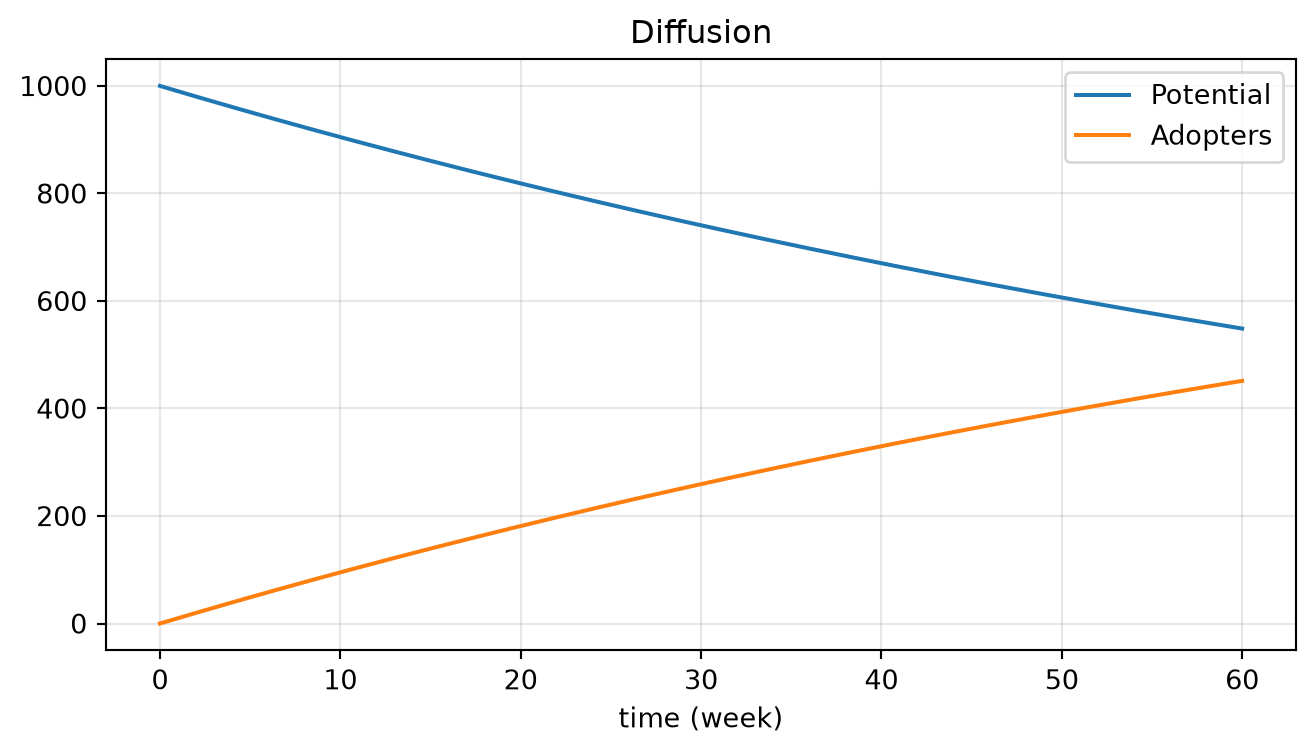

In [10]:
run = dif.run(imitation_q=0)
print(run.loc[[10.0, 20.0, 60.0], "Adopters"].round(0))
dif.plot(run)

## Where next

- Back in the app: the [S-shaped growth](https://waelrash1.github.io/loopbricks/#/learn/s-shaped) module has the diagrams and exercises behind this notebook.
- When the reinforcing loop decides *who* wins rather than how many, you get lock-in: see [Reinforcing feedback, path dependence and lock-in](https://waelrash1.github.io/loopbricks/#/learn/lock-in).
- The growth and decay building blocks are in [First-order feedback](https://waelrash1.github.io/loopbricks/#/learn/first-order). For more on epidemics and diffusion, see Sterman 2000, ch. 9.